In [ ]:
"""
Figure 7 - Linear regression between annual cumulative PDH (KAN_U) and the percentage increase in mean summer velocity relative to the subsequent mean winter velocity at LEV6.
Author: Hannah Picton 
Date: 27th March 2026
Description: This notebook plots the relationship between annual cumulative PDH at KAN_U and the percentage increase in mean summer velocity relative to the subsequent 
mean winter velocity observed at LEV6. PDH data is derived from hourly data from the automatic weather station (AWS) at KAN_U, which is made available through PROMICE 
(http://www.promice.dk). Ice surface velocity data for 2009-2012 can be found at Tedstone & Nienow (2018; https://doi.org/10.5285/1f69fba3-4c62-47ad-8119-08cfeec05e46) 
and for 2021-2023 at Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668).
"""

# Import libraries 
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import linregress
from matplotlib.ticker import FuncFormatter

# -- PROVIDE PATH TO AWS DATA FROM KAN_U --
kan_u_hourly = pd.read_csv('.../data/KAN_U_hour.csv') # UPDATE FILEPATH

# Prepare AWS data from KAN_U, calculating annual cumulative PDH for 2009-2023
kan_u_hourly['time'] = pd.to_datetime(kan_u_hourly['time'])
kan_u_hourly.set_index('time', inplace=True)
kan_u_filtered = kan_u_hourly.loc[(kan_u_hourly.index >= '2009-05-01') & (kan_u_hourly.index < '2024-05-01')].copy()
kan_u_filtered['PDH'] = kan_u_filtered['t_u'].clip(lower=0) # Clip negative values for PDH calculation
kan_u_filtered['offset_year'] = (kan_u_filtered.index - pd.DateOffset(months=4)).year
pdh_kan_u_annual = kan_u_filtered.groupby('offset_year')['PDH'].sum() # Calculate cumulative PDH for each year (1 May - 30 April)
mean_pdh_kan_u = pdh_kan_u_annual.mean() # Calculate mean annual cumulative PDH

# -- PROVIDE PATH TO ICE DISPLACEMENT DATA (LEV6) --
displacement_data_path = '.../data/' # UPDATE FILEPATH
displacement_folders = ['seasonal_annual_2009_2013', 'seasonal_annual_2020_2024']
site_lev6 = 'lev6'
plot_color = "#14213d"

# Prepare ice displacement data for plotting, calculating the percentage increase in mean summer velocity relative to the subsequent mean winter velocity at LEV6. 
def process_displacement_data(base_path, folders, site_name):
    dfs = []
    for folder in folders:
        files = glob.glob(os.path.join(base_path, folder, f"{site_name}*.csv"))
        for file in files:
            dfs.append(pd.read_csv(file))
    site_df = pd.concat(dfs, ignore_index=True)
    site_df['period'] = site_df['period'].str.capitalize()
    pivot = site_df.pivot_table(index='year', columns='period', values='vel_m_yr')
    pivot['pct_increase'] = ((pivot['Summer'] - pivot['Winter']) / pivot['Winter']) * 100
    return pivot.reset_index()
lev6_disp = process_displacement_data(displacement_data_path, displacement_folders, site_lev6)

# Merge the displacement data with the PDH data and perform linear regression analysis
pdh_df = pdh_kan_u_annual.reset_index().rename(columns={'offset_year': 'year', 'PDH': 'annual_pdh'})
lev6_final = lev6_disp.merge(pdh_df, on='year').dropna(subset=['pct_increase', 'annual_pdh'])
slope, intercept, r_val, p_val, stderr = linregress(lev6_final['annual_pdh'], lev6_final['pct_increase'])
print(f"Linear Regression Results:\nSlope: {slope:.4f}\nIntercept: {intercept:.2f}\nR-value: {r_val:.4f}\nR-squared: {r_val**2:.4f}\nP-value: {p_val:.4f}\nStandard Error: {stderr:.4f}")


Linear Regression Results:
Slope: 0.0112
Intercept: -2.94
R-value: 0.8633
R-squared: 0.7453
P-value: 0.0123
Standard Error: 0.0029


In [8]:
# Define functions for plotting 
# --- p-value formatter ---
def p_fmt(p):
    if p < 0.001:
        return r"$\leq 0.001$"
    elif p < 0.01:
        return r"$\leq 0.01$"
    elif p < 0.02:
        return r"$\leq 0.02$"
    elif p < 0.05:
        return r"$\leq 0.05$"
    else:
        return rf"$= {p:.3f}$"

# --- plus/minus formatter with 0dp ---
def plus_minus_formatter_1dp(value, pos):
    if value > 0:
        return rf"$+{value:.0f}$"
    elif value < 0:
        return rf"${value:.0f}$"
    else:
        return r"$0$"

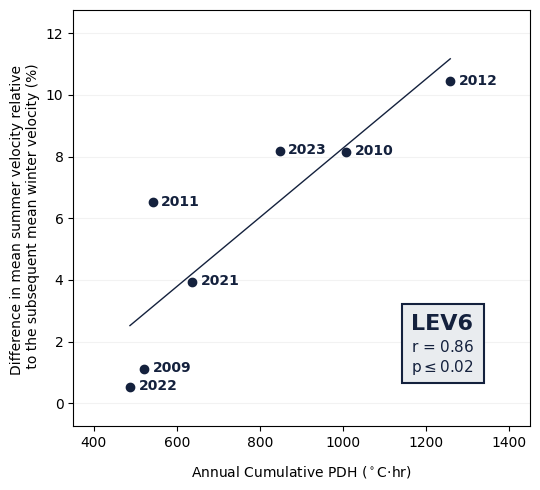

In [9]:
# Plot linear regression between annual cumulative PDH (KAN_U) and the percentage increase in mean summer velocity relative to the subsequent mean winter velocity at LEV6.
plt.figure(figsize=(5.5,5))
col_lev6 = "#14213d"
plt.scatter(lev6_final['annual_pdh'], lev6_final['pct_increase'], marker='o', color=col_lev6, zorder=5)
for _, row in lev6_final.iterrows():
    plt.text(row['annual_pdh'] + 21, row['pct_increase'] - 0.1, str(int(row['year'])), fontsize=10, color='#14213d', fontweight='bold', zorder=6)
x_vals = np.linspace(lev6_final['annual_pdh'].min(), lev6_final['annual_pdh'].max(), 100)
plt.plot(x_vals, intercept + slope * x_vals, color=col_lev6, linewidth=1, zorder=5)
rect = patches.Rectangle((0.72, 0.105), 0.18, 0.19, linewidth=1.5, edgecolor=col_lev6, facecolor='#e9ecef', transform=plt.gca().transAxes, zorder=4)
plt.gca().add_patch(rect)
plt.text(0.74, 0.27, "LEV6", transform=plt.gca().transAxes, color=col_lev6, fontsize=16, fontweight='bold', va='top', zorder=5)
plt.text(0.74, 0.21, rf"r = ${r_val:.2f}$" + "\np" + p_fmt(p_val), transform=plt.gca().transAxes, color=col_lev6, fontsize=11, va='top', zorder=5)
plt.ylim(-0.75, 12.75)
plt.xlim(350, 1450)
plt.grid(axis='y', linestyle='-', alpha=0.1, color='gray')
plt.xlabel('Annual Cumulative PDH ($^\circ$C$\cdot$hr)', labelpad=10)
plt.ylabel("Difference in mean summer velocity relative \n to the subsequent mean winter velocity (%)")
plt.tight_layout()
plt.show()